# **4 Intraday Backtesting Mistakes (and How to Fix Them)**

A backtest on hourly bars can look perfectly reasonable while the calculations underneath it are wrong. This notebook walks through four common mistakes on real data, each with a simple fix.

1. Labelling a bar's close with the time of its open
2. Measuring every intraday return close-to-close
3. Treating the backtest as proof
4. Treating overnight gaps as if they were just another bar

## **Imports**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

## **Example Data - Hourly**

Hourly bars for a small basket of stocks from Yahoo Finance.

In [2]:
# Hourly bars over a fixed window
START, END = '2025-10-31', '2026-10-31'

data_yf = yf.download('AAPL', start=START, end=END, interval='1h', auto_adjust=True, progress=False)

# Single ticker: drop the ticker level so columns are Open, Close, ...
data = data_yf.copy()
data.columns = data.columns.droplevel('Ticker')
data.columns.name = None

---
## **Big picture: Looking at one trading session with hourly returns**

Characteristics of hourly returns:

1. The first mark is the open of the first bar.
2. The last mark is the close of the final bar.
3. Besides these two, every other timestamp is simultaneously a close and an open.
4. Bar 7 is half the length of the other bars - 30 minutes.

At first glance, this seems pretty simple. It's easy to understand but sometimes difficult to properly simulate, especially if you want to build a general simulation that works for any interval class.

<br>
<img src="images/session_marks.png" alt="One session of hourly bars: one gap, seven bars and eight marks" width="900">

---
## **Mistake 1: Labelling a Portfolio Value with the Market's Open Timestamp**

We'll start with the easiest one to get wrong. The simplest way to get returns from price data is by using the `pct_change` method on market closes. Later, we'll describe where this goes wrong, but we'll use it for this example to keep things simple.

**First, we take this approach and add the resulting returns to the table. We use the hourly data.**

In [3]:
# Simple (yet flawed) way to calculate returns
returns = data['Close'].pct_change()
data['Return'] = returns
data['Return (%)'] = returns * 100
data['Acc Factor'] = 1 + returns

data[['Open', 'Close', 'Return (%)']].head()

,Open,Close,Return (%)
Datetime,,,
2025-10-31 09:30:00-04:00,276.989990,270.380005,NaN
2025-10-31 10:30:00-04:00,270.429993,271.299988,0.340256
2025-10-31 11:30:00-04:00,271.299896,272.434998,0.418360
2025-10-31 12:30:00-04:00,272.429993,270.348785,-0.765765
2025-10-31 13:30:00-04:00,270.329987,271.809998,0.540491


**Next, we create the simplest possible portfolio: Buy and hold a single stock.**

In [4]:
# Bankroll at time 0 or initial bankroll
br0 = 10_000
# Creating a buy-and-hold portfolio
portfolio_1 = br0 * data['Acc Factor'].fillna(1).cumprod()

**⚠️ Mistake 1 happens here: using the datetime index from the yfinance dataframe**

In [5]:
portfolio_1.index = data.index
portfolio_1.head()

Datetime
2025-10-31 09:30:00-04:00    10000.000000
2025-10-31 10:30:00-04:00    10034.025553
2025-10-31 11:30:00-04:00    10076.003870
2025-10-31 12:30:00-04:00     9998.845348
2025-10-31 13:30:00-04:00    10052.888255
Name: Acc Factor, dtype: float64

**What's wrong?**

Since you went from close-to-close, this assumes that every portfolio snapshot actually occurs at the close, not the open. Why does this matter? The index from the yfinance dataframe uses the datetime corresponding with the open and doesn't give us the closing time.

| Datetime | Open | Close |
| --- | --- | --- |
| 2025-10-31 10:30:00-04:00 | 270.429993 | 271.299988 |
| 2025-10-31 11:30:00-04:00 | 271.299896 | 272.434998 |

You have to deduce the closing timestamps yourself. But how?

**❌ Things that don't work**

So just add one hour, right? **No.** Remember from earlier that the closing bar is 30 minutes while the others are one hour.

Okay... how about if you just use the following timestamp instead of the current? That has problems as well. If we did this, the final bar would end up referencing the opening datetime for the next day instead of the close that occurs 30-minutes later. Also, what happens if there is a missing bar.

**✅ What to do instead**

Each time of day must be mapped to a closing time. In general for a given interval, every open time corresponds to exactly one closing time. The exception is on half-days. Depending on the trading frequency you're working with, this means you'd need a different map for each interval length.

Luckily, portfolio-forecast comes with a special function, `close_times`, that simplifies the process. Give it the index from the yfinance dataframe and it converts it to closing times. It automatically detects the interval and it uses the official NYSE calendar to detect half-days.

In [6]:
from portfolio_forecast.utils import close_times

portfolio_1.index = close_times(data.index)
portfolio_1.head(10)

Datetime
2025-10-31 10:30:00-04:00    10000.000000
2025-10-31 11:30:00-04:00    10034.025553
2025-10-31 12:30:00-04:00    10076.003870
2025-10-31 13:30:00-04:00     9998.845348
2025-10-31 14:30:00-04:00    10052.888255
2025-10-31 15:30:00-04:00    10063.799322
2025-10-31 16:00:00-04:00     9995.191772
2025-11-03 10:30:00-05:00     9898.291296
2025-11-03 11:30:00-05:00     9861.676523
2025-11-03 12:30:00-05:00     9894.777677
Name: Acc Factor, dtype: float64

---
## **Mistake 2: Measuring Every Return Close-to-Close**

Even after fixing the first mistake, we're still not done.

If we go close-to-close on every bar, the first return of each session includes the overnight gap. The big problem here is that we measured the last close of a session to the first close of the next session, giving you no control of what happens at the open of a trading session. Keep in mind, your final portfolio value wouldn't be affected for a buy-and-hold, but the strict close-to-close method prohibits you from simulating a trade at the market open. Ideally, you should be able to make a trade at the open or close of any candlestick.

We will learn more about why this is an even bigger issue for mistake 4. If you're making mistake 2, you're guaranteed to make mistake 4.

**Here's what to do for hourly data in a given session:**

1. Measure the first return of each session as open-to-close
2. Measure the rest of the session returns close-to-close up to the close of the final session candle
3. Measure the return of the overnight gap separately - close of the current session to the open of the following

**First, we calculate bar returns and gap returns separately, then concatenate them**

In [7]:
day = pd.Series(data.index.date)
first = ~day.duplicated().to_numpy()               # first bar of each session
last = ~day.duplicated(keep='last').to_numpy()     # last bar of each session

# Bar returns: open-to-close for a first bar, otherwise close-to-close
bar_returns = data['Close'] / np.where(first, data['Open'], data['Close'].shift()) - 1

# Gap returns: a session's last close to the next session's open, indexed at that session's close
gap_returns = data['Open'].shift(-1) / data['Close'] - 1
gap_returns.index = close_times(data.index)
gap_returns = gap_returns[last].dropna()

# Combine returns into one vector and derive accumulation factor
returns = pd.concat([bar_returns, gap_returns]).sort_index()
cum_factor = (returns + 1).fillna(1).cumprod()

**Then, we build the buy-and-hold portfolio**

In [8]:
# Create the portfolio where the initial bankroll is invested at the first open
portfolio_2 = pd.Series(np.zeros(returns.shape[0]+1))
portfolio_2.iloc[0]  = br0
portfolio_2.iloc[1:] = br0 * cum_factor
# Each value sits where its return ends: the start of the next return, then the final close
portfolio_2.index = returns.index.append(close_times(data.index)[-1:])

---
## **Mistake 3: Treating the Backtest as Proof**

Suppose every calculation above is now correct. The backtest is still **one path**: the one sequence of returns that happened to occur. It tells you what the strategy did, not what it will do, and not how much of the result was luck.

**To show this, we split the backtest in two pieces. Their is quite a disparity in performance between the two halves.**

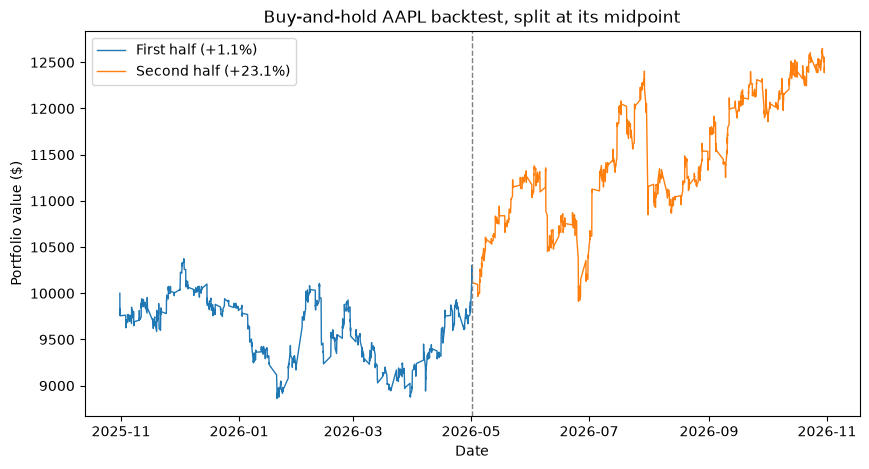

In [9]:
# Split the backtest at the session close nearest its midpoint
session_closes = close_times(data.index)[last]
mid_close = session_closes[len(session_closes) // 2 - 1]

# Backtest value over time, coloured by half
halves = {'First half': (portfolio_2.loc[:mid_close], 'tab:blue'),
          'Second half': (portfolio_2.loc[mid_close:], 'tab:orange')}

fig, ax = plt.subplots(figsize=(10, 5))
for name, (values, color) in halves.items():
    total_return = values.iloc[-1] / values.iloc[0] - 1
    ax.plot(values.index, values, color=color, linewidth=1, label=f'{name} ({total_return:+.1%})')
ax.axvline(mid_close, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('Date')
ax.set_ylabel('Portfolio value ($)')
ax.set_title('Buy-and-hold AAPL backtest, split at its midpoint')
ax.legend()
plt.show()

In [10]:
from portfolio_forecast.performance import performance_report

print('FIRST HALF')
first_half = performance_report(portfolio_2.loc[:mid_close], display=True)

print('\nSECOND HALF')
second_half = performance_report(portfolio_2.loc[mid_close:], display=True)

FIRST HALF

            PORTFOLIO PERFORMANCE REPORT            
----------------------------------------------------
  Total Time         :  0.50 years (182 days)
  Periods            :   982 returns
                      RETURNS                       
----------------------------------------------------
  Initial Bankroll   :     10000.00
  Final Bankroll     :     10114.08
  Total Return       :        1.14%
  CAGR               :        2.31%
----------------------------------------------------
  Actual Yearly Returns:
    - 2025            :       -1.86%  (62 days)
    - 2026            :        3.06%  (120 days)
                        RISK                        
----------------------------------------------------
  Volatility         :       23.00%
  Downside Vol       :       15.06%
  Gap Vol (per gap)  :        0.75%
  Bar Vol (per bar)  :        0.49%
  Max Drawdown       :       14.58%
  Sharpe Ratio       :         0.43
  Sortino Ratio      :         0.66


SECOND HALF

 

**Clearly, the backtest doesn't tell us enough. To quantify uncertainty, we can use Monte Carlo simulation. That brings us to the next common mistake.**

---
## **Mistake 4: Pooling Gaps with the Other Returns in Monte Carlo Simulations**

Assuming we've handled mistake 2, we can address mistake 4. It's a known phenomenon, that overnight gap volatility differs fundamentally from bar volatility. For this reason, you shouldn't pool them together when fitting a time-series model or using a Monte Carlo simulator.

**To demonstrate this, we put the gap and bar returns from this session on the same time scale and then compare their distributions.**

In [11]:
hour = pd.Timedelta(hours=1)
closes = close_times(data.index)

def to_one_hour(log_returns, rho):
    """Put log returns of length rho (in hours) on a one-hour footing:
    drift scales with rho, volatility with sqrt(rho)."""
    m_hat = log_returns.sum() / rho.sum()               # average drift per hour
    return m_hat + (log_returns - rho * m_hat) / np.sqrt(rho)

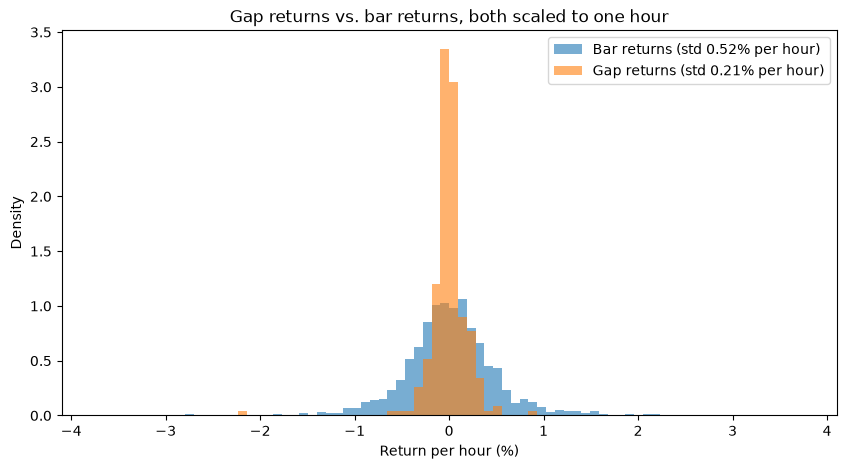

In [12]:
# Bars: 1 hour, or 0.5 for a session's last bar
bar_hours = ((closes - data.index) / hour).to_numpy()
bar_hourly = np.expm1(to_one_hour(np.log1p(bar_returns), bar_hours))

# Gaps: clock time from a session's close to the next session's open
# (17.5 hours on a weeknight, 65.5 over a weekend)
gap_hours = pd.Series((data.index[1:] - closes[:-1]) / hour, index=closes[:-1])
gap_hours = gap_hours.reindex(gap_returns.index).to_numpy()
gap_hourly = np.expm1(to_one_hour(np.log1p(gap_returns), gap_hours))

# Both distributions per hour, on the same axes with shared bins
lim = max(gap_hourly.abs().max(), bar_hourly.abs().max()) * 100
bins = np.linspace(-lim, lim, 81)

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(bar_hourly * 100, bins=bins, density=True, alpha=0.6, color='tab:blue',
        label=f'Bar returns (std {bar_hourly.std() * 100:.2f}% per hour)')
ax.hist(gap_hourly * 100, bins=bins, density=True, alpha=0.6, color='tab:orange',
        label=f'Gap returns (std {gap_hourly.std() * 100:.2f}% per hour)')
ax.set_xlabel('Return per hour (%)')
ax.set_ylabel('Density')
ax.set_title('Gap returns vs. bar returns, both scaled to one hour')
ax.legend()
plt.show()

**Gaps display lower volatility as expected. How do we account for this in the Monte Carlo? Let's demonstrate with a nonparametric approach.**

**First:**

1. Label every past return. Use classify_returns to mark each return in the backtest as a gap, a regular bar, or irregular (one that spans a missing bar).
2. Pool the gap returns. Collect every past gap return as it is, with no scaling. Irregular returns are left out of both pools.
3. Pool the bar returns on a full-hour footing. Collect every past bar return, then scale the 30-minute last bars up to a full hour so that everything in the pool is comparable.

In [13]:
from portfolio_forecast.utils import classify_returns, next_trading_dates

# Train on the first half of the backtest, then forecast every session of the second half
train = portfolio_2.loc[:mid_close]
n_sims, n_sessions = 10000, int((session_closes > mid_close).sum())
rng = np.random.default_rng(42)

# Label every historical return: gap, regular (a bar) or irregular (a missing bar)
classes = classify_returns(train)
past_returns = train.pct_change().iloc[1:]

# Pool together the gap returns - no scaling applied
gap_pool = past_returns[classes == 'gap'].to_numpy()

# Pool together the bar returns - scaling applied
bar_past = past_returns[classes == 'regular']
# Rho is calculated as the bar length divided by the reference bar length
bar_rho = (train.index.to_series().diff().iloc[1:][classes == 'regular'] / pd.Timedelta(hours=1)).to_numpy()
log_bar = np.log1p(bar_past)
m_hat = log_bar.sum() / bar_rho.sum()                              # average drift per full bar
bar_pool = np.expm1(to_one_hour(log_bar, bar_rho)).to_numpy()

**To finish:**

1. Lay out the future timeline. Ask next_trading_dates for the marks of every session in the second half: each session's open, then each of its bar closes. Every mark comes labelled as a gap or a bar.
2. Draw a return for every future mark from its own pool. For each of the 1,000 simulated paths, pick a random past gap return for every open mark and a random past bar return for every bar close, sampling with replacement.
3. Shrink the draws for the short bars. The bar pool holds full-hour returns, so any draw that lands on a 30-minute last bar is scaled back down to that length: its drift by one half, its volatility by the square root of one half.
4. Compound the returns into paths. Starting from the last backtest value, multiply through each path's returns in order, which gives 1,000 possible portfolio values at every future mark.

In [14]:
# Lay out the future marks: each session's open (a gap), then its bar closes
layout = next_trading_dates(train, n_sessions)
is_gap = layout.classes == 'gap'

# Draw each future mark from the pool of its own class
draws = np.empty((n_sims, len(layout.dates)))
draws[:, is_gap] = rng.choice(gap_pool, size=(n_sims, is_gap.sum()))
draws[:, ~is_gap] = rng.choice(bar_pool, size=(n_sims, (~is_gap).sum()))

# Shrink the draws for short future bars back to their length (tau = 0.5 for a last bar)
tau = layout.tau[~is_gap]
draws[:, ~is_gap] = np.expm1(tau * m_hat + np.sqrt(tau) * (np.log1p(draws[:, ~is_gap]) - m_hat))

# Compound the returns into paths of growth multiples: column 0 is the last training value, as 1.0
paths = np.column_stack([np.ones(n_sims), np.cumprod(1 + draws, axis=1)])

**Next, we can plot the actual portfolio value over the forecasted ranged.**

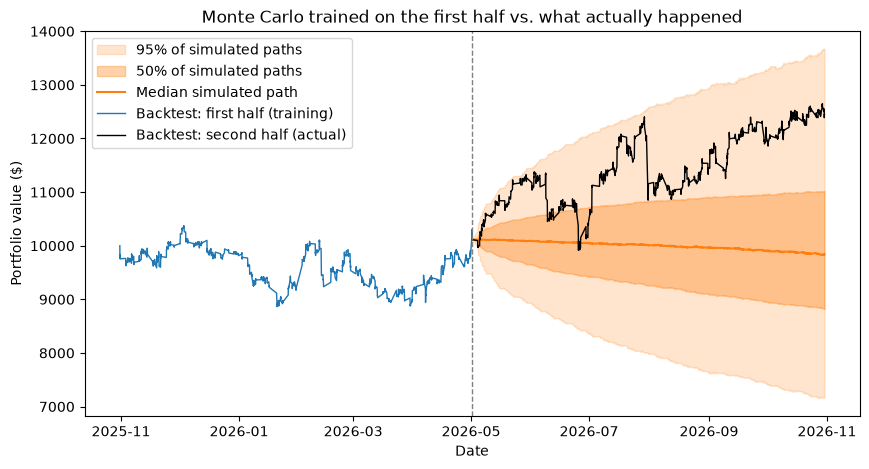

In [15]:
def plot_forecast_vs_actual(train, actual, paths, future_dates,
                            title='Monte Carlo trained on the first half vs. what actually happened'):
    """Draw simulated paths as a fan, in dollars, over the backtest they were trained on
    and the values that actually followed.

    train        : backtest values the simulation was trained on
    actual       : backtest values after the training period
    paths        : simulated growth multiples, one row per path, column 0 = 1.0
    future_dates : the future marks, one per column of paths after column 0
    """
    # Put the simulated paths in dollars: growth multiples times the last training value
    fan_dates = train.index[-1:].append(future_dates)
    fan = paths * train.iloc[-1]
    low, q1, median, q3, high = np.percentile(fan, [2.5, 25, 50, 75, 97.5], axis=0)

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.fill_between(fan_dates, low, high, color='tab:orange', alpha=0.2, label='95% of simulated paths')
    ax.fill_between(fan_dates, q1, q3, color='tab:orange', alpha=0.35, label='50% of simulated paths')
    ax.plot(fan_dates, median, color='tab:orange', linewidth=1.5, label='Median simulated path')
    ax.plot(train.index, train, color='tab:blue', linewidth=1, label='Backtest: first half (training)')
    ax.plot(actual.index, actual, color='black', linewidth=1, label='Backtest: second half (actual)')
    ax.axvline(train.index[-1], color='gray', linestyle='--', linewidth=1)
    ax.set_xlabel('Date')
    ax.set_ylabel('Portfolio value ($)')
    ax.set_title(title)
    ax.legend(loc='upper left')
    plt.show()
    return fig, ax

fig, ax = plot_forecast_vs_actual(train, portfolio_2.loc[mid_close:], paths, layout.dates)

## **Recommendation: Use `portfolio-forecast` to do all this in a few lines of code**

/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_28821/1249539939.py:5: UserWarning: 1 session(s) have no bar at the open, first 2026-02-02 13:30:00-05:00: each open mark is the first available bar's open, labelled at its start, and the return into it is irregular
  backtest = simulate_buy_and_hold(data_yf, {'AAPL': 1.0}, br0=br0)
/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_28821/1249539939.py:5: UserWarning: 2 return(s) are irregular, first ending 2025-12-01 09:30:00-05:00: a held symbol is stale (no own price) at either end, or a scheduled bar is missing for every symbol. They stay in the values and metrics and are left out of Monte Carlo fits
  backtest = simulate_buy_and_hold(data_yf, {'AAPL': 1.0}, br0=br0)
/var/folders/4k/9t00rt713w3fsg126syp21gc0000gn/T/ipykernel_28821/1249539939.py:12: UserWarning: nonparametric_monte_carlo: on intraday history sim_length counts sessions, not bars (changed in 0.4.0): sim_length=126 gives 1008 future marks, ending at the

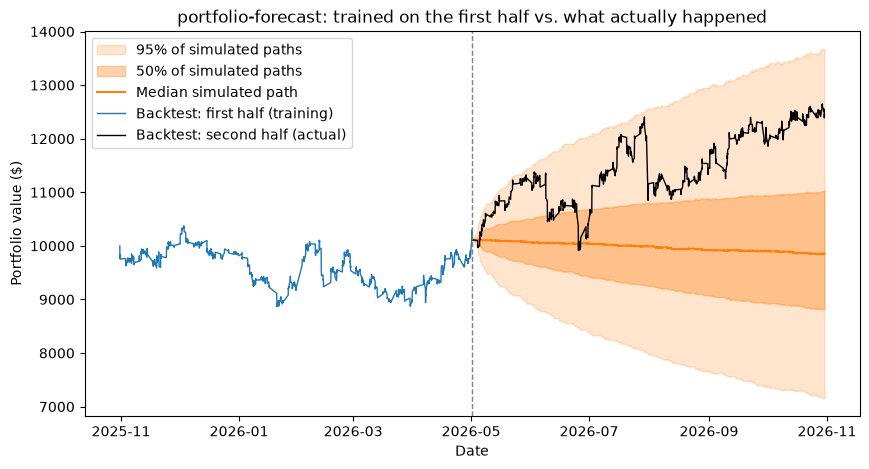

In [ ]:
from portfolio_forecast.forecast import nonparametric_monte_carlo
from portfolio_forecast.performance import simulate_buy_and_hold

# Backtest: buy at the first open, with a value at each session's open and each bar's close
backtest = simulate_buy_and_hold(data_yf, {'AAPL': 1.0}, br0=br0)

# Train on the first half of the backtest: its values and the class of each of its returns
train_values = backtest.values.loc[:mid_close]
train_classes = backtest.classes.loc[:mid_close]

# 1,000 paths over every session of the second half, gaps and bars drawn from their own pools
mc = nonparametric_monte_carlo(train_values, sim_length=n_sessions, n_sims=n_sims, random_state=42,
                               classes=train_classes)

# The simulated range on top of the full backtest
fig, ax = plot_forecast_vs_actual(train_values, backtest.values.loc[mid_close:], mc.paths, mc.dates,
                                  title='portfolio-forecast: trained on the first half vs. what actually happened')